<a href="https://colab.research.google.com/github/Chithra679/AI-based-project/blob/main/Aquaguard_Hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# AquaGuard: Two houses sharing one water tank

data = {
    "House": ["House 1", "House 2"],
    "Expected_Usage_L": [300, 300],
    "Actual_Usage_L": [350, 250]
}

df = pd.DataFrame(data)

print("AQUAGUARD - SMART WATER MONITORING")
print("\nDaily Water Usage:")
print(df)

AQUAGUARD - SMART WATER MONITORING

Daily Water Usage:
     House  Expected_Usage_L  Actual_Usage_L
0  House 1               300             350
1  House 2               300             250


In [2]:
# Calculate extra or saved water
df["Difference_L"] = (
    df["Actual_Usage_L"] - df["Expected_Usage_L"]
)

# Alert if usage is more than 110% of expected usage
df["Status"] = df.apply(
    lambda row: "HIGH USAGE ALERT"
    if row["Actual_Usage_L"] > row["Expected_Usage_L"] * 1.10
    else "Normal",
    axis=1
)

print(df.to_string(index=False))

for _, row in df.iterrows():
    if row["Status"] == "HIGH USAGE ALERT":
        print(f"\nWarning: {row['House']} has unusually high usage!")
    else:
        print(f"\n{row['House']}: Water usage is within the limit.")

  House  Expected_Usage_L  Actual_Usage_L  Difference_L           Status
House 1               300             350            50 HIGH USAGE ALERT
House 2               300             250           -50           Normal


House 2: Water usage is within the limit.


In [3]:
tank_capacity = 1000  # Tank capacity in liters
starting_water = 1000  # Tank starts full

total_usage = df["Actual_Usage_L"].sum()
remaining_water = max(0, starting_water - total_usage)

print("SHARED WATER TANK STATUS")
print("------------------------")
print("Tank capacity:", tank_capacity, "liters")
print("Starting water:", starting_water, "liters")
print("House 1 usage:", df.loc[0, "Actual_Usage_L"], "liters")
print("House 2 usage:", df.loc[1, "Actual_Usage_L"], "liters")
print("Total daily usage:", total_usage, "liters")
print("Estimated remaining water:", remaining_water, "liters")

if remaining_water < 200:
    print("Alert: Tank water is running low!")
else:
    print("Tank status: Sufficient water remaining.")

SHARED WATER TANK STATUS
------------------------
Tank capacity: 1000 liters
Starting water: 1000 liters
House 1 usage: 350 liters
House 2 usage: 250 liters
Total daily usage: 600 liters
Estimated remaining water: 400 liters
Tank status: Sufficient water remaining.


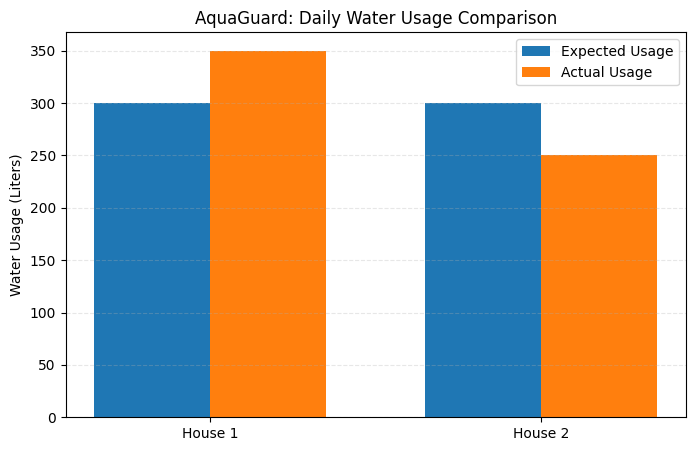

In [4]:
plt.figure(figsize=(8, 5))

x = range(len(df))
width = 0.35

plt.bar(
    [i - width/2 for i in x],
    df["Expected_Usage_L"],
    width,
    label="Expected Usage"
)

plt.bar(
    [i + width/2 for i in x],
    df["Actual_Usage_L"],
    width,
    label="Actual Usage"
)

plt.xticks(list(x), df["House"])
plt.ylabel("Water Usage (Liters)")
plt.title("AquaGuard: Daily Water Usage Comparison")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.show()

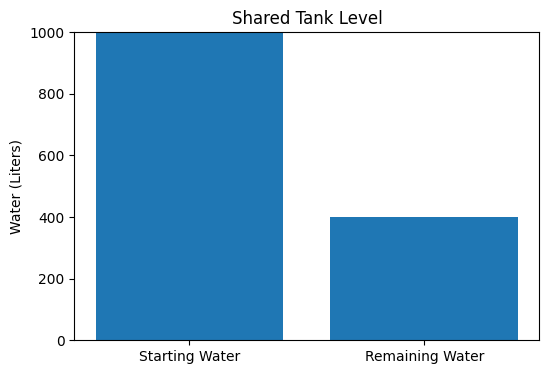

In [5]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Starting Water", "Remaining Water"],
    [starting_water, remaining_water]
)

plt.ylabel("Water (Liters)")
plt.title("Shared Tank Level")
plt.ylim(0, tank_capacity)
plt.show()

In [6]:
print("AQUAGUARD RECOMMENDATIONS")
print("-------------------------")

for _, row in df.iterrows():
    if row["Status"] == "HIGH USAGE ALERT":
        print(
            f"{row['House']}: Check taps, pipes, and "
            "daily water use for possible wastage."
        )
    else:
        print(
            f"{row['House']}: Continue monitoring and "
            "use water responsibly."
        )

print("\nBoth houses should check the shared tank regularly.")
print("AquaGuard helps residents understand usage and save water.")

AQUAGUARD RECOMMENDATIONS
-------------------------
House 1: Check taps, pipes, and daily water use for possible wastage.
House 2: Continue monitoring and use water responsibly.

Both houses should check the shared tank regularly.
AquaGuard helps residents understand usage and save water.


In [7]:
df.to_csv("AquaGuard_Two_Houses_Report.csv", index=False)

from google.colab import files
files.download("AquaGuard_Two_Houses_Report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
!pip -q install gradio

In [10]:
import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

def aquaguard_dashboard(
    house1_usage,
    house2_usage,
    tank_capacity,
    starting_water
):
    # Calculate total water usage
    total_usage = house1_usage + house2_usage

    # Estimate remaining tank water
    remaining = max(0, starting_water - total_usage)
    overflow_usage = max(0, total_usage - starting_water)

    # Create house data
    data = pd.DataFrame({
        "House": ["House 1", "House 2"],
        "Expected Usage (L)": [300, 300],
        "Actual Usage (L)": [house1_usage, house2_usage]
    })

    data["Difference (L)"] = (
        data["Actual Usage (L)"] -
        data["Expected Usage (L)"]
    )

    data["Status"] = data.apply(
        lambda row: "HIGH USAGE ALERT"
        if row["Actual Usage (L)"] >
           row["Expected Usage (L)"] * 1.10
        else "Normal",
        axis=1
    )

    # Create messages
    if remaining < 200:
        tank_message = (
            "LOW TANK WARNING: Check the water level "
            "and plan a refill."
        )
    else:
        tank_message = "Tank level is sufficient."

    if overflow_usage > 0:
        tank_message += (
            f"\nUsage exceeds the starting water by "
            f"{overflow_usage} L. A refill may be needed."
        )

    report = (
        "## 💧 AQUAGUARD LIVE DASHBOARD\n\n"
        f"### 🏠 House 1: {house1_usage:.0f} L/day\n"
        f"Expected: 300 L | Status: {data.iloc[0]['Status']}\n\n"
        f"### 🏡 House 2: {house2_usage:.0f} L/day\n"
        f"Expected: 300 L | Status: {data.iloc[1]['Status']}\n\n"
        f"### 🚰 Shared Tank\n"
        f"- Tank capacity: {tank_capacity:.0f} L\n"
        f"- Starting water: {starting_water:.0f} L\n"
        f"- Combined daily usage: {total_usage:.0f} L\n"
        f"- Estimated remaining: {remaining:.0f} L\n\n"
        f"### ⚠️ Tank Alert\n{tank_message}\n\n"
        "### 🌱 Recommendations\n"
    )

    for _, row in data.iterrows():
        if row["Status"] == "HIGH USAGE ALERT":
            report += (
                f"- {row['House']}: Review water usage "
                "and check taps or pipes for possible leaks.\n"
            )
        else:
            report += (
                f"- {row['House']}: Continue responsible "
                "water use.\n"
            )

    if overflow_usage > 0:
        report += (
            "- Combined usage exceeds available starting "
            "water; plan a refill.\n"
        )

    # Comparison chart
    fig, ax = plt.subplots(figsize=(7, 4))
    houses = ["House 1", "House 2"]
    expected = [300, 300]
    actual = [house1_usage, house2_usage]
    x = range(2)
    width = 0.35

    ax.bar(
        [i - width/2 for i in x],
        expected,
        width,
        label="Expected"
    )
    ax.bar(
        [i + width/2 for i in x],
        actual,
        width,
        label="Actual"
    )

    ax.set_xticks(list(x))
    ax.set_xticklabels(houses)
    ax.set_ylabel("Water usage (liters/day)")
    ax.set_title("Daily Water Usage Comparison")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()

    # Tank level chart
    tank_fig, tank_ax = plt.subplots(figsize=(7, 2.5))
    tank_ax.barh(
        ["Remaining water"],
        [remaining],
        label="Remaining"
    )
    tank_ax.set_xlim(0, max(tank_capacity, 1))
    tank_ax.set_xlabel("Liters")
    tank_ax.set_title("Estimated Shared Tank Level")
    tank_ax.grid(axis="x", alpha=0.25)
    tank_fig.tight_layout()

    # Downloadable report
    data["Tank Capacity (L)"] = tank_capacity
    data["Starting Water (L)"] = starting_water
    data["Estimated Remaining (L)"] = remaining

    csv_path = "AquaGuard_Dashboard_Report.csv"
    data.to_csv(csv_path, index=False)

    return report, fig, tank_fig, csv_path


with gr.Blocks(title="AquaGuard Water Monitor") as demo:
    gr.Markdown(
        """
        # 💧 AquaGuard
        ### Smart Water Monitoring for Two Neighboring Houses
        Monitor usage, compare consumption, and estimate
        the remaining water in your shared tank.

        **Demo mode:** All readings are simulated.
        """
    )

    with gr.Row():
        house1 = gr.Slider(
            0, 1000, value=350, step=10,
            label="🏠 House 1 Usage (liters/day)"
        )
        house2 = gr.Slider(
            0, 1000, value=250, step=10,
            label="🏡 House 2 Usage (liters/day)"
        )

    with gr.Row():
        capacity = gr.Number(
            value=1000, label="Tank Capacity (liters)"
        )
        starting = gr.Number(
            value=1000, label="Starting Water (liters)"
        )

    update_btn = gr.Button(
        "Update Dashboard", variant="primary"
    )

    summary = gr.Markdown()
    usage_chart = gr.Plot(label="Usage Comparison")
    tank_chart = gr.Plot(label="Tank Level")

    download_report = gr.File(label="Download CSV Report")

    inputs = [house1, house2, capacity, starting]
    outputs = [
        summary, usage_chart, tank_chart, download_report
    ]

    update_btn.click(
        fn=aquaguard_dashboard,
        inputs=inputs,
        outputs=outputs
    )

    # Show results immediately when the dashboard opens
    demo.load(
        fn=aquaguard_dashboard,
        inputs=inputs,
        outputs=outputs
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://32af618b4f971b933d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
